# 3) Thermodynamics of the SCO Transition

This notebook inspects the SCOPE Systems and retrieves the electronic and vibrational enthalpy and entropy terms to compute T1/2

**Important:** Notebooks must be executed in order. You're expected to run notebooks 0, 1 and 2 first.

In [1]:
import csv
import os
import sys

import numpy as np
import scope

sys.path.insert(0, os.path.abspath('..'))
from local_functions import *

import matplotlib.pyplot as plt

## User Configuration

In [ ]:
data_path     = "/Users/sergivela/Documents/SCOPE/ATLAS/Data/"                                                          # Update with your path
analysis_path = "/Users/sergivela/Documents/SCOPE/ATLAS/Analyses/1-TMC_Thermodynamics/"                  # Update with your path
env_path      = "/Users/sergivela/Documents/SCOPE/ATLAS/Data/scope_env_atlas.npy"                                       # Update with your path
figures_path  = "/Users/sergivela/Documents/SCOPE/ATLAS/Analyses/1-TMC_Thermodynamics/Figures/"          # Update with your path
save_figures  = True
tables_path   = os.path.join(figures_path, 'Tables') + os.sep

if not save_figures:
    figures_path = None

# Normalizes the configured strings and defines the analysis output folder.
data_path     = os.path.abspath(os.path.expanduser(data_path)) + os.sep
env_path      = os.path.abspath(os.path.expanduser(env_path))
analysis_path = os.path.abspath(os.path.expanduser(analysis_path)) + os.sep
outputs_path  = analysis_path + "Outputs/"

# Checks SCOPE version
expected_scope_version = "0.9.6"
installed_scope_version = getattr(scope, "__version__", None)
if installed_scope_version != expected_scope_version:
    raise RuntimeError(f"This analysis requires SCOPE {expected_scope_version}; the active environment provides {installed_scope_version!r}.")

# These folders are required, together with the system-dedicated folders inside.
required_data_paths = [data_path + "2-Systems/", data_path + "3-Computations/"]
missing_paths       = [path for path in required_data_paths if not os.path.isdir(path)]
if missing_paths:
    raise FileNotFoundError(f"Missing required SCO ATLAS data directories: {missing_paths}")
if not os.path.isfile(env_path):
    raise FileNotFoundError(f"SCOPE environment file not found: {env_path}")
os.makedirs(outputs_path, exist_ok=True)
os.makedirs(tables_path, exist_ok=True)

# Loads Environment
env = scope.load_binary(env_path)

# Paths of additional files
unique_csv_path               = outputs_path + "unique_systems.csv"
thermo_unique_path            = outputs_path + "unique_thermodynamic_data.csv"
vibrational_bins_path         = outputs_path + "unique_vibrational_data_bins.csv"
td_histograms_figure_path     = figures_path + "TD_histograms_denticity.png" if figures_path else None
t12_data_figure_path          = figures_path + "T12_vs_dHelec_denticity_data.png" if figures_path else None
t12_fit_figure_path           = figures_path + "T12_vs_dHelec_denticity_fit.png" if figures_path else None
dsvib_bins_figure_path        = figures_path + "dSvib_binned_contribution.png" if figures_path else None
dhvib_bins_figure_path        = figures_path + "dHvib_binned_contribution.png" if figures_path else None
mode_fractions_figure_path    = figures_path + "vibrational_mode_fractions.png" if figures_path else None
entropy_per_mode_figure_path  = figures_path + "vibrational_entropy_per_mode.png" if figures_path else None
structural_data_path         = outputs_path + "unique_structural_data.csv"
gap_comparison_path          = outputs_path + "electronic_gap_comparison.csv"
gap_summary_path             = outputs_path + "electronic_gap_summary.csv"
gap_extremes_table_path      = tables_path + "electronic_gap_extremes_table.tex"
family_map_paths             = [analysis_path + f"Figures/HTML/Grid_Map_d{d}.csv" for d in [1, 2, 3, 6]]

print(f"SCOPE version:      {installed_scope_version}")
print(f"Data directory:     {data_path}")
print(f"SCOPE environment:  {env_path}")
print(f"Analysis outputs:   {outputs_path}")
print(f"Manuscript Figures: {figures_path}")

SCOPE version:      0.9.6
Data directory:     /Users/sergivela/Documents/SCOPE/Database_SCO/Data/
SCOPE environment:  /Users/sergivela/Documents/SCOPE/Database_SCO/Data/scope_env_atlas.npy
Analysis outputs:   /Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/1-TMC_Thermodynamics/Outputs/
Manuscript Figures: /Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/1-TMC_Thermodynamics/Figures/


### Database

In [3]:
# Loads finished systems that are "unique" (i.e. non-repeated)

unique_systems = []
with open(unique_csv_path, newline="") as f:
    reader = csv.DictReader(f)
    for row in reader:
        sys = scope.load_binary(f"{data_path}/{row['path']}")
        sys.set_paths_from_environment(env)
        unique_systems.append(sys)

print(f"{len(unique_systems)} Unique systems loaded")

602 Unique systems loaded


## Prepares Thermodynamic Data for all Unique Systems

In [4]:
thermo_unique_line = [] # For Storage
dHelecs = []            # For easy access to values
dHvibs  = [] 
dSvibs  = [] 
dSelecs = [] 
dGtots  = [] 
T12s    = []

for sys in unique_systems:
    exists, this_branch = sys.find_branch('isolated')
    relative_path       = f"2-Systems/{sys.refcode}/{sys.refcode}.npy"

    # dHelec
    if 'dHelec' in this_branch.results.keys(): 
        dHelec = this_branch.results["dHelec"].value*scope.constants.har2kJmol
    else:
        dHelec = None
    dHelecs.append(float(dHelec))

    # dHvib
    if 'dHvib' in this_branch.results.keys(): 
        dHvib = this_branch.results["dHvib"].find_value_with_property("temperature", 298).value*scope.constants.har2kJmol
    else:
        dHvib = None
    dHvibs.append(float(dHvib))

    # dSvib
    if 'dSvib' in this_branch.results.keys(): 
        dSvib = this_branch.results["dSvib"].find_value_with_property("temperature", 298).value*scope.constants.har2kJmol*298
    else:
        dSvib = None
    dSvibs.append(float(dSvib))

    # dSelec
    if 'dSelec' in this_branch.results.keys(): 
        dSelec = this_branch.results["dSelec"].value*scope.constants.har2kJmol*298
    else:
        dSelec = None
    dSelecs.append(float(dSelec))

    # dGtot
    if 'dGtot' in this_branch.results.keys(): 
        dGtot = this_branch.results["dGtot"].find_value_with_property("temperature", 298).value*scope.constants.har2kJmol
    else:
        dGtot = None
    dGtots.append(float(dGtot))

    # T12
    if 'T12' in this_branch.results.keys(): 
        T12 = this_branch.results["T12"].value
        if T12 is None:   T12 = "None"
        elif T12 == "":   T12 = "None"
    else:
        T12 = "None"
    T12s.append(T12)

    # Denticity
    found, mol = sys.find_source("ref_hs_mol")
    if found:
        ligands = mol.ligands
        assert ligands is not None, f"Ligands not found in the reference molecule of {sys.refcode}."
        if all(lig.__eq__(ligands[0], with_graph=False) for lig in ligands):
            homoleptic = True
            if ligands[0].get_denticity()==1:    dent = int(1) 
            elif ligands[0].get_denticity()==2:  dent = int(2)
            elif ligands[0].get_denticity()==3:  dent = int(3)
            elif ligands[0].get_denticity()==6:  dent = int(6)
        else:
            homoleptic = False
            dent = "unknown"
    else:
        print(f"Reference molecule not found for {sys.refcode}. Cannot determine homolepticity or denticity.")
        homoleptic = "unknown"
        dent = "unknown"

    thermo_unique_line.append({"refcode": sys.refcode_wo_digits, "path": relative_path, "status": "finished", "dHelec[kJ/mol]": np.round(dHelec,6), "dHvib[kJ/mol](T=298K)": np.round(dHvib,6), "dSvib·T[kJ/mol](T=298K)": np.round(dSvib,6), "dSelec·T[kJ/mol](T=298K)": np.round(dSelec,6), "dGtot[kJ/mol](T=298K)": np.round(dGtot,6), "T12[K]": T12, "homoleptic": homoleptic, "denticity": dent}) 

with open(thermo_unique_path, "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=["refcode", "path", "status", "dHelec[kJ/mol]", "dHvib[kJ/mol](T=298K)", "dSvib·T[kJ/mol](T=298K)", "dSelec·T[kJ/mol](T=298K)", "dGtot[kJ/mol](T=298K)", "T12[K]", "homoleptic", "denticity"])
    writer.writeheader()
    writer.writerows(thermo_unique_line)

print("Results stored in:", thermo_unique_path)


Results stored in: /Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/1-TMC_Thermodynamics/Outputs/unique_thermodynamic_data.csv


## Histograms

In [ ]:
# Combined thermodynamic histograms by denticity

histogram_specs = [
    {
        "column": "dHelec[kJ/mol]",
        "xlabel": r"$\Delta H_{\mathrm{elec}}$ [kJ/mol]",
        "title": r"$\Delta H_{\mathrm{elec}}$",
        "fmt": ".1f",
    },
    {
        "column": "dHvib[kJ/mol](T=298K)",
        "xlabel": r"$\Delta H_{\mathrm{vib}}$(298 K) [kJ/mol]",
        "title": r"$\Delta H_{\mathrm{vib}}$",
        "fmt": ".1f",
    },
    {
        "column": "dSvib·T[kJ/mol](T=298K)",
        "xlabel": r"$T\Delta S_{\mathrm{vib}}$(298 K) [kJ/mol]",
        "title": r"$T\Delta S_{\mathrm{vib}}$",
        "fmt": ".1f",
    },
    {
        "column": "T12[K]",
        "xlabel": r"$T_{1/2}$ [K]",
        "title": r"$T_{1/2}$",
        "fmt": ".0f",
        "filter": lambda row: row["T12[K]"] != "None",
    },
]

denticity_specs = [
    ("1", "d = 1", "purple"),
    ("2", "d = 2", "green"),
    ("3", "d = 3", "blue"),
    ("6", "d = 6", "orange"),
    ("unknown", "Heteroleptic", "pink"),
    ("all", "All", "black"),
]

sco_compatible_ranges = {
    "dHelec[kJ/mol]": (8.3, 47.7),
    "dHvib[kJ/mol](T=298K)": (-8.8, 1.1),
    "dSvib·T[kJ/mol](T=298K)": (5.4, 41.8),
    "T12[K]": (0.0, 400.0),
}

nbins = 20
fig, axs = plt.subplots(
    len(denticity_specs), len(histogram_specs),
    figsize=(12.5, 9.0),
    constrained_layout=True,
    sharey="row",
)

for j, spec in enumerate(histogram_specs):
    rows = filter_rows(thermo_unique_path, spec.get("filter", lambda row: row[spec["column"]] != "None"))
    values_by_denticity = {
        denticity: [float(row[spec["column"]]) for row in rows if row["denticity"] == denticity]
        for denticity, _, _ in denticity_specs[:-1]
    }
    values_by_denticity["all"] = [
        value
        for denticity in values_by_denticity
        for value in values_by_denticity[denticity]
    ]

    to_plot = values_by_denticity["all"]
    xmin, xmax = min(to_plot), max(to_plot)
    if xmin == xmax:
        bins = [xmin - 0.5, xmax + 0.5]
    else:
        bin_width = (xmax - xmin) / nbins
        bins = [xmin + i * bin_width for i in range(nbins + 1)]

    for i, (denticity, row_label, color) in enumerate(denticity_specs):
        ax = axs[i, j]
        values = values_by_denticity[denticity]
        ax.hist(values, bins=bins, color=color, edgecolor="black", alpha=0.8)
        for boundary in sco_compatible_ranges[spec["column"]]:
            ax.axvline(boundary, color="dimgray", linestyle="--", linewidth=1.4, zorder=2)
        ax.tick_params(axis="both", which="major", length=2, width=1, direction="out", labelsize=9)
        ax.tick_params(axis="both", which="minor", length=1, width=1, direction="out")
        ax.grid(axis="y", linestyle="--", alpha=0.6)

        if j == 0:
            ax.set_ylabel(f"{row_label}\nCount", fontsize=11)
        if i == 0:
            ax.set_title(spec["title"], fontsize=14)
        if i == len(denticity_specs) - 1:
            ax.set_xlabel(spec["xlabel"], fontsize=11)

        if values:
            text_x = 0.03 if spec["column"] == "dHvib[kJ/mol](T=298K)" else 0.98
            text_ha = "left" if spec["column"] == "dHvib[kJ/mol](T=298K)" else "right"
            ax.text(
                text_x, 0.90,
                f"median={np.median(values):{spec['fmt']}}\n"
                f"mean={np.mean(values):{spec['fmt']}}",
                transform=ax.transAxes,
                ha=text_ha,
                va="top",
                fontsize=9,
                bbox=dict(boxstyle="round", facecolor="white", edgecolor="black", alpha=0.90),
                zorder=5,
            )

if td_histograms_figure_path:
    fig.savefig(td_histograms_figure_path, dpi=400)
plt.show()



## Correlation between dHelec and T

### Data extraction and fitting

In [6]:
filtered = filter_rows(thermo_unique_path, lambda row: row["T12[K]"] != "None")
h1 = [float(row["dHelec[kJ/mol]"]) for row in filtered if row["denticity"] == "1"]
h2 = [float(row["dHelec[kJ/mol]"]) for row in filtered if row["denticity"] == "2"]
h3 = [float(row["dHelec[kJ/mol]"]) for row in filtered if row["denticity"] == "3"]
h6 = [float(row["dHelec[kJ/mol]"]) for row in filtered if row["denticity"] == "6"]
ho = [float(row["dHelec[kJ/mol]"]) for row in filtered if row["denticity"] == "unknown"]
t1 = [float(row["T12[K]"]) for row in filtered if row["denticity"] == "1"]
t2 = [float(row["T12[K]"]) for row in filtered if row["denticity"] == "2"]
t3 = [float(row["T12[K]"]) for row in filtered if row["denticity"] == "3"]
t6 = [float(row["T12[K]"]) for row in filtered if row["denticity"] == "6"]
to = [float(row["T12[K]"]) for row in filtered if row["denticity"] == "unknown"]

## Monodentate
coef1 = np.polyfit(h1, t1, 1)
x1_fit = np.linspace(min(h1), max(h1), 200)
y1_fit = coef1[0] * x1_fit + coef1[1]
r1 = 1 - np.sum((np.array(t1) - (coef1[0] * np.array(h1) + coef1[1])) ** 2) / np.sum((np.array(t1) - np.mean(t1)) ** 2)

## Bidentate
coef2  = np.polyfit(h2, t2, 1)
x2_fit = np.linspace(min(h2), max(h2), 200)
y2_fit = coef2[0] * x2_fit + coef2[1]
r2 = 1 - np.sum((np.array(t2) - (coef2[0] * np.array(h2) + coef2[1])) ** 2) / np.sum((np.array(t2) - np.mean(t2)) ** 2)

## Tridentate
coef3  = np.polyfit(h3, t3, 1)
x3_fit = np.linspace(min(h3), max(h3), 200)
y3_fit = coef3[0] * x3_fit + coef3[1]
r3 = 1 - np.sum((np.array(t3) - (coef3[0] * np.array(h3) + coef3[1])) ** 2) / np.sum((np.array(t3) - np.mean(t3)) ** 2)

## Hexadentate
coef6  = np.polyfit(h6, t6, 1)
x6_fit = np.linspace(min(h6), max(h6), 200)
y6_fit = coef6[0] * x6_fit + coef6[1]
r6 = 1 - np.sum((np.array(t6) - (coef6[0] * np.array(h6) + coef6[1])) ** 2) / np.sum((np.array(t6) - np.mean(t6)) ** 2)

## Heteroleptic
coefo  = np.polyfit(ho, to, 1)
xo_fit = np.linspace(min(ho), max(ho), 200)
yo_fit = coefo[0] * xo_fit + coefo[1]
ro = 1 - np.sum((np.array(to) - (coefo[0] * np.array(ho) + coefo[1])) ** 2) / np.sum((np.array(to) - np.mean(to)) ** 2)

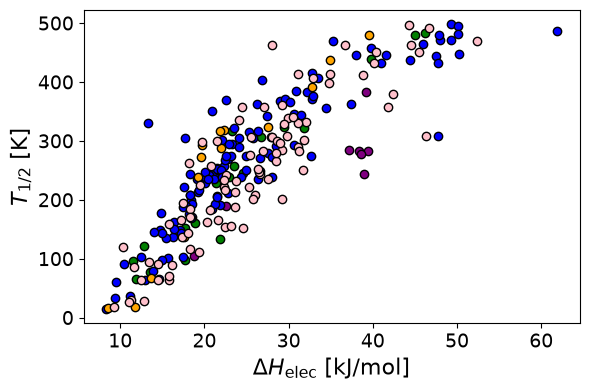

In [7]:
fig, ax = plt.subplots(figsize=(6, 4), tight_layout=True)
ax.scatter(h1, t1, color='purple', edgecolor='black')
ax.scatter(h2, t2, color='green', edgecolor='black')
ax.scatter(h3, t3, color='blue', edgecolor='black')
ax.scatter(h6, t6, color='orange', edgecolor='black')
ax.scatter(ho, to, color='pink', edgecolor='black')
ax.set_ylabel(r"$T_{1/2}$ [K]", fontsize=16)
ax.set_xlabel(r"$\Delta H_{\mathrm{elec}}$ [kJ/mol]", fontsize=16)
ax.tick_params(axis='both', which='major', labelsize=14)
if t12_data_figure_path:
    fig.savefig(t12_data_figure_path, dpi=400)

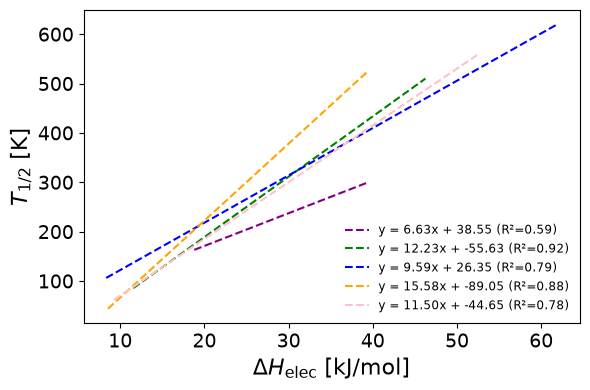

In [8]:
fig, ax = plt.subplots(figsize=(6, 4), tight_layout=True)
ax.plot(x1_fit, y1_fit, color='purple', linestyle='--', label=f'y = {coef1[0]:.2f}x + {coef1[1]:.2f} (R²={r1:.2f})')
ax.plot(x2_fit, y2_fit, color='green', linestyle='--',  label=f'y = {coef2[0]:.2f}x + {coef2[1]:.2f} (R²={r2:.2f})')
ax.plot(x3_fit, y3_fit, color='blue', linestyle='--',   label=f'y = {coef3[0]:.2f}x + {coef3[1]:.2f} (R²={r3:.2f})')
ax.plot(x6_fit, y6_fit, color='orange', linestyle='--', label=f'y = {coef6[0]:.2f}x + {coef6[1]:.2f} (R²={r6:.2f})')
ax.plot(xo_fit, yo_fit, color='pink', linestyle='--',   label=f'y = {coefo[0]:.2f}x + {coefo[1]:.2f} (R²={ro:.2f})')
ax.set_ylabel(r"$T_{1/2}$ [K]", fontsize=16)
ax.set_xlabel(r"$\Delta H_{\mathrm{elec}}$ [kJ/mol]", fontsize=16)
#ax.set_ylim(0,600)
#ax.set_xlim(0,70)
ax.tick_params(axis='both', which='major', labelsize=14)
ax.legend(frameon=False, fontsize=8.5)
#ax.legend(loc="upper left", fontsize=10, frameon=False)
if t12_fit_figure_path:
    fig.savefig(t12_fit_figure_path, dpi=400)

## Thermodynamic ranges for SCO below 400 K

In [9]:
# Thermodynamic ranges compatible with a SCO transition below 400 K

sco_t12_min = 0.0
sco_t12_max = 400.0

thermo_columns = {
    "dHelec[kJ/mol]": "dHelec[kJ/mol]",
    "dHvib[kJ/mol]": "dHvib[kJ/mol](T=298K)",
    "T*dSvib[kJ/mol]": "dSvib·T[kJ/mol](T=298K)",
}

sco_rows = []
with open(thermo_unique_path, newline="") as f:
    reader = csv.DictReader(f)
    for row in reader:
        t12 = as_float(row.get("T12[K]"))
        if t12 is not None and sco_t12_min < t12 <= sco_t12_max:
            sco_rows.append(row)

compatible_ranges = []
for label, column in thermo_columns.items():
    values = np.array([as_float(row[column]) for row in sco_rows], dtype=float)
    compatible_ranges.append({
        "quantity": label,
        "n": len(values),
        "min": round(np.min(values), 2),
        "max": round(np.max(values), 2),
        "p10": round(np.percentile(values, 10), 2),
        "p90": round(np.percentile(values, 90), 2),
        "median": round(np.median(values), 2),
    })

print(f"SCO-compatible window: {len(sco_rows)} systems with {sco_t12_min:.0f} < T1/2 <= {sco_t12_max:.0f} K")
compatible_ranges


SCO-compatible window: 212 systems with 0 < T1/2 <= 400 K


[{'quantity': 'dHelec[kJ/mol]',
  'n': 212,
  'min': np.float64(8.32),
  'max': np.float64(47.7),
  'p10': np.float64(13.49),
  'p90': np.float64(31.68),
  'median': np.float64(22.0)},
 {'quantity': 'dHvib[kJ/mol]',
  'n': 212,
  'min': np.float64(-8.78),
  'max': np.float64(1.1),
  'p10': np.float64(-6.48),
  'p90': np.float64(-2.94),
  'median': np.float64(-4.75)},
 {'quantity': 'T*dSvib[kJ/mol]',
  'n': 212,
  'min': np.float64(5.37),
  'max': np.float64(41.79),
  'p10': np.float64(13.86),
  'p90': np.float64(24.95),
  'median': np.float64(18.62)}]

# Frequency-Resolved Vibrational Contributions

The HS--LS vibrational entropy and enthalpy differences are decomposed into the same frequency windows at 298.15 K. Both quantities are evaluated with the SCOPE harmonic-oscillator functions, `get_Svib` and `get_Hvib`, using their default treatment of imaginary frequencies, and stored in a shared CSV cache.

In [10]:
TEMPERATURE = 298.15
FREQ_BINS_CM = np.array([1, 50, 100, 200, 400, 800, 1200, 1600, 4000], dtype=float)
DENTICITIES_TO_COMPARE = ['1', '2', '3', '6']
ENTROPY_METHOD = 'scope.thermodynamics.get_Svib(HO, imaginary=ignore; SCOPE 0.9.6 defaults)'
ENTHALPY_METHOD = 'scope.thermodynamics.get_Hvib(imaginary=ignore; SCOPE 0.9.6 defaults)'

overwrite = True

In [11]:
required_columns = {
    'refcode', 'denticity', 'homoleptic', 'HS_minimum_state', 'LS_minimum_state', 'temperature[K]',
    'entropy_method', 'enthalpy_method', 'bin_low[cm-1]', 'bin_high[cm-1]',
    'bin_label[cm-1]', 'HS_Svib[J·mol-1·K-1]', 'LS_Svib[J·mol-1·K-1]',
    'dSvib[J·mol-1·K-1]', 'HS_Hvib[kJ·mol-1]', 'LS_Hvib[kJ·mol-1]',
    'dHvib[kJ·mol-1]', 'HS_n_modes', 'LS_n_modes', 'd_n_modes',
    'HS_mode_fraction', 'LS_mode_fraction', 'd_mode_fraction',
    'HS_mean_S_per_mode[J·mol-1·K-1]', 'LS_mean_S_per_mode[J·mol-1·K-1]',
    'd_mean_S_per_mode[J·mol-1·K-1]',
}

thermo_by_refcode = {row.get('refcode', row.get('id')): row for row in read_csv(thermo_unique_path)}
expected_refcodes = set(thermo_by_refcode)
expected_bins = set(zip(FREQ_BINS_CM[:-1], FREQ_BINS_CM[1:]))

if os.path.exists(vibrational_bins_path) and not overwrite:
    vibrational_bin_rows = read_csv(vibrational_bins_path)
    cached_columns = set(vibrational_bin_rows[0]) if vibrational_bin_rows else set()
    cached_refcodes = {row['refcode'] for row in vibrational_bin_rows}
    if required_columns - cached_columns:
        print('The cached table is missing required columns; rebuilding it.')
        overwrite = True
    elif {(float(row['bin_low[cm-1]']), float(row['bin_high[cm-1]'])) for row in vibrational_bin_rows} != expected_bins:
        print('The cached table uses different frequency bins; rebuilding it.')
        overwrite = True
    elif cached_refcodes != expected_refcodes:
        print('The cached table does not match the current unique-system set; rebuilding it.')
        overwrite = True
    elif any(
        row['entropy_method'] != ENTROPY_METHOD or row['enthalpy_method'] != ENTHALPY_METHOD
        for row in vibrational_bin_rows
    ):
        print('The cached table uses different thermochemistry settings; rebuilding it.')
        overwrite = True
    else:
        print(f'Loaded {len(vibrational_bin_rows)} frequency-bin rows from {vibrational_bins_path}')

if overwrite or not os.path.exists(vibrational_bins_path):
    vibrational_bin_rows, failures = build_vibrational_bin_rows(
        unique_systems, thermo_by_refcode, TEMPERATURE, FREQ_BINS_CM,
        ENTROPY_METHOD, ENTHALPY_METHOD,
    )

    with open(vibrational_bins_path, 'w', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=list(vibrational_bin_rows[0]))
        writer.writeheader()
        writer.writerows(vibrational_bin_rows)
    print(f'Wrote {len(vibrational_bin_rows)} frequency-bin rows to {vibrational_bins_path}')
    print(f'Failures: {len(failures)}')
    if failures:
        print(failures[:10])

Wrote 4816 frequency-bin rows to /Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/1-TMC_Thermodynamics/Outputs/unique_vibrational_data_bins.csv
Failures: 0


In [12]:
# FEPHAK is excluded because its ligand-composition descriptor cannot be generated.
homoleptic_bin_rows = [
    row for row in vibrational_bin_rows
    if str(row['homoleptic']).lower() == 'true'
    and str(row['denticity']) in DENTICITIES_TO_COMPARE
    and row['refcode'] != 'FEPHAK'
]
bin_order = [f'{int(low)}-{int(high)}' for low, high in zip(FREQ_BINS_CM[:-1], FREQ_BINS_CM[1:])]

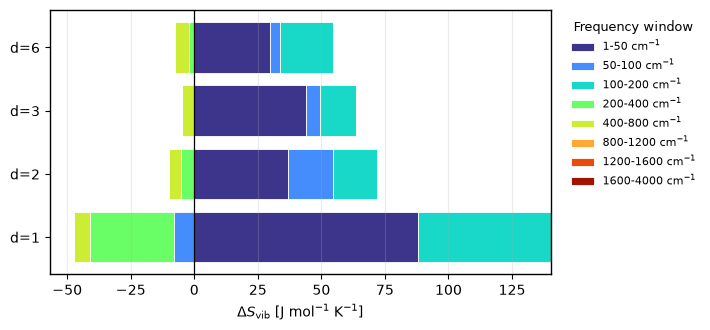

(<Figure size 720x340 with 1 Axes>,
 <Axes: xlabel='$\\Delta S_{\\mathrm{vib}}$ [J mol$^{-1}$ K$^{-1}$]'>)

In [13]:
dSvib_values, ordered = mean_vibrational_bin_values(homoleptic_bin_rows, 'dSvib[J·mol-1·K-1]', DENTICITIES_TO_COMPARE, bin_order)
plot_frequency_contributions(dSvib_values, ordered, bin_order, r'$\Delta S_{\mathrm{vib}}$ [J mol$^{-1}$ K$^{-1}$]', dsvib_bins_figure_path)

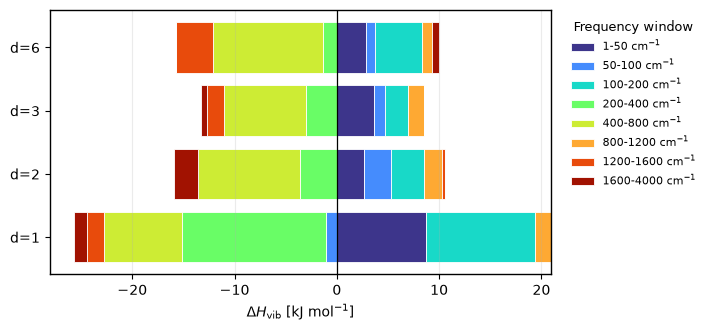

(<Figure size 720x340 with 1 Axes>,
 <Axes: xlabel='$\\Delta H_{\\mathrm{vib}}$ [kJ mol$^{-1}$]'>)

In [14]:
dHvib_values, ordered = mean_vibrational_bin_values(
    homoleptic_bin_rows, 'dHvib[kJ·mol-1]', DENTICITIES_TO_COMPARE, bin_order
)
plot_frequency_contributions(
    dHvib_values, ordered, bin_order,
    r'$\Delta H_{\mathrm{vib}}$ [kJ mol$^{-1}$]',
    dhvib_bins_figure_path,
)

## Electronic-Energy Extremes

Compare the central electronic-energy window with the negative and positive tails separately. No additional structural or statistical exclusion is applied. Energies and optimized structural descriptors are read from the existing CSV files; molecular size, ligand formulae and SMILES are taken from the stored reference molecules. Atom counts include H atoms and exclude counterions and solvent outside the SCO molecule.

The motif flags identify simple compositions checked against representative ligand SMILES. They are descriptive markers, not a complete ligand classification. Existing grid-map family assignments are included when available, but notebook 4 is not required to run this comparison.

In [25]:
gap_threshold = 50.0  # kJ/mol; values exactly at the limits remain within the window.

gap_thermo = {row['refcode']: row for row in read_csv(thermo_unique_path)}
gap_structure = {row['id']: row for row in read_csv(structural_data_path)}
gap_families = {}
for map_path in family_map_paths:
    if os.path.isfile(map_path):
        for row in read_csv(map_path):
            gap_families[row['Refcode']] = row

gap_rows = []
for system in unique_systems:
    refcode = system.refcode_wo_digits
    row = electronic_gap_comparison_row(
        system, gap_thermo[refcode], gap_structure[refcode], gap_threshold,
    )
    family = gap_families.get(refcode, {})
    row['Family'] = family.get('family_id', '')
    row['Core Label'] = family.get('Core-ring family', '')
    gap_rows.append(row)

assert len(gap_rows) == len(gap_thermo), 'The system list and thermodynamic CSV do not match.'
write_csv_rows(gap_comparison_path, gap_rows)
print(f'Comparison of {len(gap_rows)} complexes saved to: {gap_comparison_path}')


Comparison of 602 complexes saved to: /Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/1-TMC_Thermodynamics/Outputs/electronic_gap_comparison.csv


In [26]:
energy_groups = ['negative extreme', 'within window', 'positive extreme']
comparison_metrics = [
    'dHelec[kJ/mol]', 'Num Atoms', 'Num Heavy Atoms',
    'HS dFeN [Angstrom]', 'LS dFeN [Angstrom]',
    'HS Sigma [deg]', 'LS Sigma [deg]', 'HS CShM', 'LS CShM',
]

gap_summary = []
for group in energy_groups:
    selected = [row for row in gap_rows if row['Energy Group'] == group]
    summary = {
        'Energy Group': group,
        'Num Entries': len(selected),
        'Fraction [%]': 100 * len(selected) / len(gap_rows),
        'Num Homoleptic': sum(row['homoleptic'] for row in selected),
        'Num Heteroleptic': sum(not row['homoleptic'] for row in selected),
    }
    for metric in comparison_metrics:
        values = [row[metric] for row in selected if row[metric] is not None]
        summary['Median ' + metric] = float(np.median(values)) if values else None
    gap_summary.append(summary)

write_csv_rows(gap_summary_path, gap_summary)
print(f"{'Subset':<19} {'N':>4} {'Atoms':>8} {'Heavy':>8} {'HS Fe-N':>9} {'LS Fe-N':>9} {'HS Sigma':>10} {'LS Sigma':>10}")
for row in gap_summary:
    print(
        f"{row['Energy Group']:<19} {row['Num Entries']:>4} "
        f"{row['Median Num Atoms']:>8.1f} {row['Median Num Heavy Atoms']:>8.1f} "
        f"{row['Median HS dFeN [Angstrom]']:>9.3f} {row['Median LS dFeN [Angstrom]']:>9.3f} "
        f"{row['Median HS Sigma [deg]']:>10.1f} {row['Median LS Sigma [deg]']:>10.1f}"
    )
print('All descriptor values in this table are medians; distances are in Angstrom and angles in degrees.')
print(f'Summary saved to: {gap_summary_path}')


Subset                 N    Atoms    Heavy   HS Fe-N   LS Fe-N   HS Sigma   LS Sigma
negative extreme      12     60.0     33.5     2.218     2.058      105.0       70.8
within window        500     67.0     41.0     2.179     1.979       94.2       57.2
positive extreme      90     79.0     49.0     2.163     1.958       84.7       53.5
All descriptor values in this table are medians; distances are in Angstrom and angles in degrees.
Summary saved to: /Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/1-TMC_Thermodynamics/Outputs/electronic_gap_summary.csv


In [27]:
motif_columns = [
    'Has Thiocyanate', 'Has Dicyanamide',
    'Has Unsubstituted Phthalocyanine', 'Has B2N4O4 Dioxime Ligand',
]
print(f"{'Ligand marker':<38} {'Negative':>9} {'Within':>9} {'Positive':>9}")
for marker in motif_columns:
    counts = []
    for group in energy_groups:
        counts.append(sum(row[marker] for row in gap_rows if row['Energy Group'] == group))
    print(f'{marker:<38} {counts[0]:>9} {counts[1]:>9} {counts[2]:>9}')

print('\nFamilies with at least three positive-tail members:')
family_counts = {}
for row in gap_rows:
    if not row['Family']:
        continue
    family_key = (row['denticity'], row['Family'])
    if family_key not in family_counts:
        family_counts[family_key] = {'total': 0, 'positive': 0}
    family_counts[family_key]['total'] += 1
    family_counts[family_key]['positive'] += row['Energy Group'] == 'positive extreme'

for (denticity, family), counts in sorted(
    family_counts.items(), key=lambda item: item[1]['positive'], reverse=True,
):
    if counts['positive'] >= 3:
        print(f"d={denticity}  {family:<8}  {counts['positive']}/{counts['total']} above +{gap_threshold:g} kJ/mol")

print('\nNegative-tail members and the ten largest positive gaps:')
negative_members = sorted(
    [row for row in gap_rows if row['Energy Group'] == 'negative extreme'],
    key=lambda row: row['dHelec[kJ/mol]'],
)
positive_members = sorted(
    [row for row in gap_rows if row['Energy Group'] == 'positive extreme'],
    key=lambda row: row['dHelec[kJ/mol]'], reverse=True,
)[:10]
for row in negative_members + positive_members:
    print(
        f"{row['refcode']:<8} {row['dHelec[kJ/mol]']:>8.2f} kJ/mol  "
        f"HS/LS Fe-N: {row['HS dFeN [Angstrom]']:.3f}/{row['LS dFeN [Angstrom]']:.3f} Angstrom  "
        f"ligands: {row['Ligand Formulae']}"
    )


Ligand marker                           Negative    Within  Positive
Has Thiocyanate                                8       121         0
Has Dicyanamide                                2         5         0
Has Unsubstituted Phthalocyanine               0         0         6
Has B2N4O4 Dioxime Ligand                      0         0         7

Families with at least three positive-tail members:
d=3  F(4,7)    15/25 above +50 kJ/mol
d=2  F(3,1)    7/7 above +50 kJ/mol
d=3  F(6,5)    7/29 above +50 kJ/mol
d=3  F(6,3)    6/8 above +50 kJ/mol
d=3  F(1,8)    3/6 above +50 kJ/mol

Negative-tail members and the ten largest positive gaps:
BUNSAF    -116.34 kJ/mol  HS/LS Fe-N: 2.237/2.140 Angstrom  ligands: H30-C20-N6
HAPDOU     -82.70 kJ/mol  HS/LS Fe-N: 2.238/2.095 Angstrom  ligands: C-N-S; H30-C42-N4-O2
WONLES     -71.89 kJ/mol  HS/LS Fe-N: 2.211/2.070 Angstrom  ligands: C-N-S; H26-C26-N8
WIDGOG     -65.97 kJ/mol  HS/LS Fe-N: 2.186/1.993 Angstrom  ligands: C2-N3; H24-C22-N6
HOLSIN     -65.80

These comparisons describe the sampled chemical space. Molecular size, ligand composition and geometry vary together, so a larger median atom count in one tail does not establish a size effect. Extreme gaps can also accompany unusually short HS or long LS Fe-N distances in structures that passed the initial structural filter. Those cases warrant inspection before assigning the entire energetic difference to ligand chemistry.

The prevalence of moderate electronic gaps supports the suitability of Fe(II)N6 coordination for competing spin states. It does not imply that every complex within the window undergoes SCO, nor that all possible Fe(II)N6 chemistry has been sampled.

In [ ]:
write_electronic_gap_extremes_table(gap_rows, gap_extremes_table_path, count=10)
print(f'ESI table saved to: {gap_extremes_table_path}')

print('\nHomoleptic d=6 complexes with negative electronic gaps:')
for row in sorted(gap_rows, key=lambda row: row['dHelec[kJ/mol]']):
    if str(row['denticity']) == '6' and row['dHelec[kJ/mol]'] < 0:
        print(f"{row['refcode']}: {row['dHelec[kJ/mol]']:.2f} kJ/mol")
